In [1]:
x=3

In [2]:
import  pandas as pd 
import seaborn as sns
import matplotlib as plt
import numpy as np


In [4]:
#importing data
healthcare = pd.read_excel(r'C:\Users\ADMIN\Desktop\mentorship\patient_records_dataset.xlsx')

In [5]:
healthcare.head(10)

,patient_id,date_of_birth,gender,height_cm,weight_kg,blood_type,systolic_bp_mmHg,diastolic_bp_mmHg,fasting_blood_sugar_mg_dl,cholesterol_mg_dl,daily_salt_intake_g,activity_hours_per_week,smoker_status,hypertension_diagnosis
0,PAT-1001,1946-03-17,Male,166.5,80.2,O+,164,97,113.0,244.7,13.2,0,Non-Smoker,1
1,PAT-1002,1992-05-08,Female,156.8,57.8,O+,137,85,97.6,178.5,9.5,1,Non-Smoker,1
2,PAT-1003,1976-04-11,Female,165.9,85.9,O+,143,81,107.5,184.8,12.1,3,Non-Smoker,1
3,PAT-1004,1980-03-03,Female,153.7,69.6,A+,136,82,107.1,225.2,6.7,2,Non-Smoker,0
4,PAT-1005,1996-10-27,Male,180.9,89.0,O+,143,85,104.0,174.4,8.0,10,Former Smoker,1
5,PAT-1006,1963-05-06,Male,164.2,74.9,A+,161,102,107.5,210.9,11.6,1,Non-Smoker,1
6,PAT-1007,1974-11-09,Male,180.3,121.0,AB-,152,91,108.0,231.1,7.6,1,Non-Smoker,1
7,PAT-1008,2003-08-06,Female,NaN,72.5,A+,137,78,109.0,195.5,10.1,0,Non-Smoker,1
8,PAT-1009,1962-11-09,Female,157.7,94.5,A+,148,91,122.8,257.2,5.2,0,Former Smoker,1
9,PAT-1010,1984-04-07,Female,175.3,91.1,A+,147,92,107.0,185.2,10.2,1,Non-Smoker,1


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
healthcare.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   patient_id                 500 non-null    object        
 1   date_of_birth              500 non-null    datetime64[ns]
 2   gender                     500 non-null    object        
 3   height_cm                  495 non-null    float64       
 4   weight_kg                  500 non-null    float64       
 5   blood_type                 498 non-null    object        
 6   systolic_bp_mmHg           500 non-null    int64         
 7   diastolic_bp_mmHg          500 non-null    int64         
 8   fasting_blood_sugar_mg_dl  500 non-null    float64       
 9   cholesterol_mg_dl          500 non-null    float64       
 10  daily_salt_intake_g        500 non-null    float64       
 11  activity_hours_per_week    500 non-null    int64         
 12  smoker_s

In [8]:
#inputing missing data
healthcare = healthcare.fillna(0)

In [10]:
#missing data in blood_type column
healthcare['blood_type'] = healthcare['blood_type'].fillna('N/A')

In [11]:
#missing data in height_cm column
healthcare['height_cm'] = healthcare['height_cm'].fillna(healthcare['height_cm'].median())

In [13]:
print(healthcare.isnull().sum())

patient_id                   0
date_of_birth                0
gender                       0
height_cm                    0
weight_kg                    0
blood_type                   0
systolic_bp_mmHg             0
diastolic_bp_mmHg            0
fasting_blood_sugar_mg_dl    0
cholesterol_mg_dl            0
daily_salt_intake_g          0
activity_hours_per_week      0
smoker_status                0
hypertension_diagnosis       0
dtype: int64


Box Plot Analysis
● Create a box plot of cholesterol_mg_dl grouped by smoker_status. Identify the
upper whisker bound, median line, and count how many extreme outliers exist
above 1. 5 × IQR. 

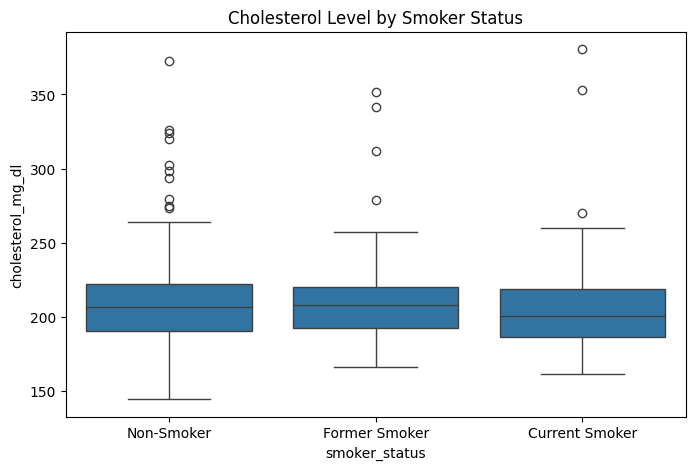

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.boxplot(x='smoker_status', y='cholesterol_mg_dl', data=healthcare)
plt.title("Cholesterol Level by Smoker Status")
plt.show()



In [ ]:

#inter quatile range (IQR) method
Q1 = healthcare['cholesterol_mg_dl'].quantile(0.25)
Q3 = healthcare['cholesterol_mg_dl'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + (1.5 * IQR)

 # Actual upper whisker value
upper_whisker = healthcare['cholesterol_mg_dl'][healthcare['cholesterol_mg_dl'] <= upper_bound].max()
 
  # Count extreme outliers above upper whisker
outliers = healthcare[healthcare['cholesterol_mg_dl'] > upper_bound]

median = healthcare['cholesterol_mg_dl'].median()

print("Upper bound:",upper_bound)
print("Upper whisker value:", upper_whisker)
print("Number of extreme outliers:", len(outliers))
print("Median cholesterol level:", median)
print("Extreme outlier values:", outliers['cholesterol_mg_dl'].values)


Upper bound: 268.1125
Upper whisker value: 264.2
Number of extreme outliers: 17
Median cholesterol level: 206.4
Extreme outlier values: [372.5 274.9 380.6 326.3 279.  279.7 352.7 302.2 312.  298.2 341.8 273.5
 320.1 293.5 351.4 324.  270. ]


In [35]:
del print

Construct side-by-side box plots for systolic_bp_mmHg broken down by
hypertension_diagnosis (0 vs 1). What does the overlap/separation between
the two boxes indicate about blood pressure as a feature?

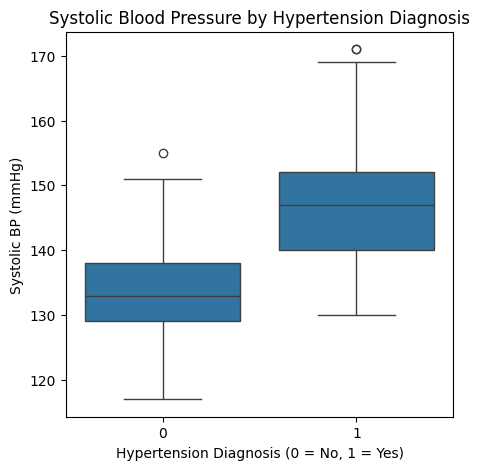

In [38]:
plt.figure(figsize=(5, 5))
sns.boxplot(x='hypertension_diagnosis', y='systolic_bp_mmHg', data=healthcare)

plt.title("Systolic Blood Pressure by Hypertension Diagnosis")
plt.xlabel("Hypertension Diagnosis (0 = No, 1 = Yes)")
plt.ylabel("Systolic BP (mmHg)")
plt.show()

The box plot shows that patients diagnosed with hypertension generally have higher systolic blood pressure than patients without hypertension.

Correlation & Supervised Learning Preparation
● What factors contribute to the hypertension diagnosis of the patients in the
dataset?
a heatmap most definately

In [39]:
# Select numerical columns
numerical_data = healthcare.select_dtypes(include=['number'])

In [40]:
numeric_cols = ['systolic_bp_mmHg', 
    'diastolic_bp_mmHg', 
    'cholesterol_mg_dl', 
    'fasting_blood_sugar_mg_dl', 
    'daily_salt_intake_g', 
    'activity_hours_per_week',
    'hypertension_diagnosis']

corr = healthcare[numeric_cols].corr()

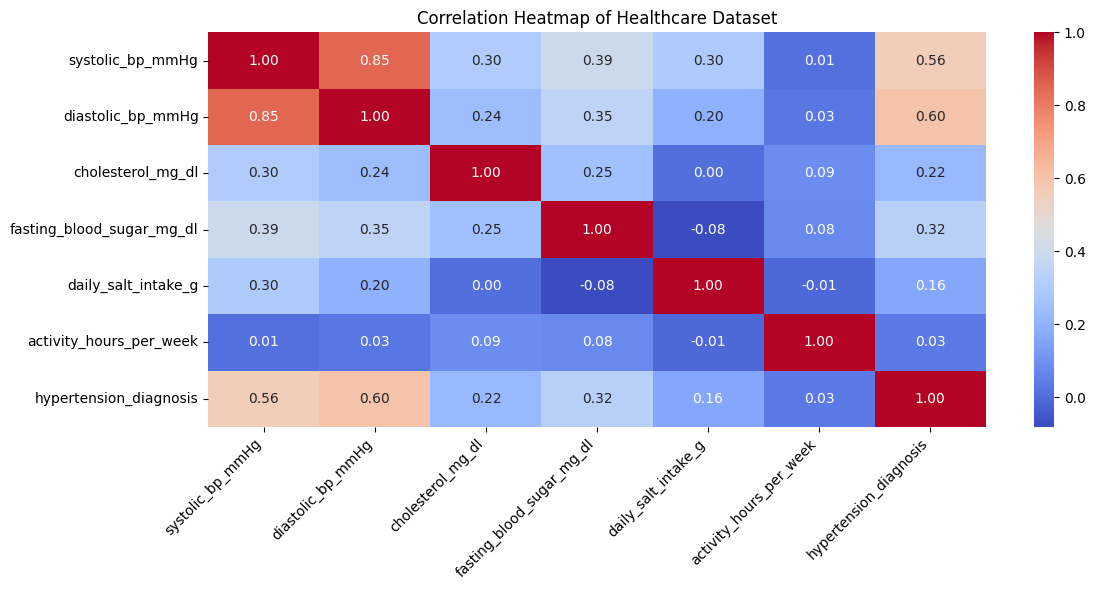

In [41]:
plt.figure(figsize=(12, 6))

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Healthcare Dataset")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Plot a scatter plot of systolic_bp_mmHg vs diastolic_bp_mmHg colored by
hypertension_diagnosis. Draw a trendline. How can continuous predictors be
used to train a logistic regression or decision tree model?

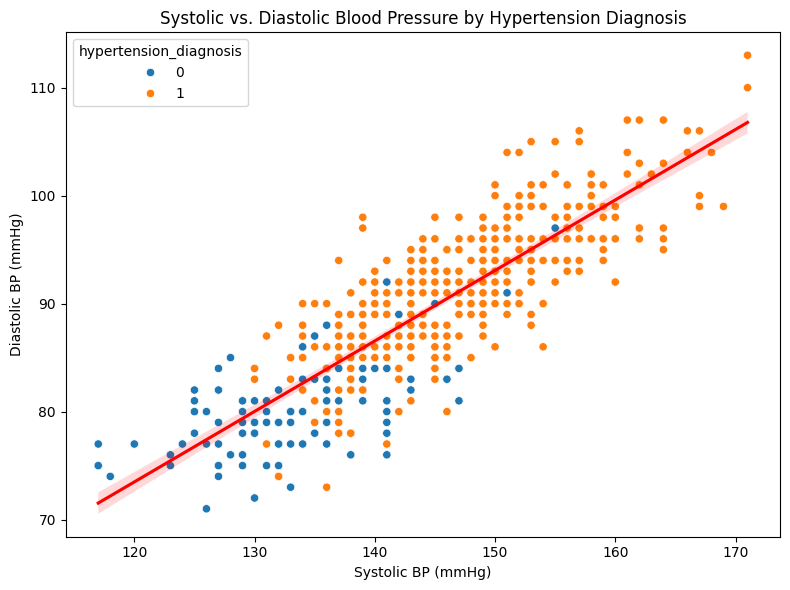

In [45]:
plt.figure(figsize=(8,6))
sns.scatterplot(x='systolic_bp_mmHg',y='diastolic_bp_mmHg',data=healthcare,hue='hypertension_diagnosis')

sns.regplot(x='systolic_bp_mmHg',y='diastolic_bp_mmHg',data=healthcare,scatter=False,color='red')
plt.title("Systolic vs. Diastolic Blood Pressure by Hypertension Diagnosis")
plt.xlabel("Systolic BP (mmHg)")
plt.ylabel("Diastolic BP (mmHg)")
plt.tight_layout()
plt.show()



0= no hypertension BLUE
1= has hypertension ORANGE

there is a positive correlation btw both BP value.
they both increase or descrease together,the blue is clutered more downwards-low BP
orange clustered upwards-high BP
